# [Bonus Tasks](svm_segm.ipynb)

In [66]:
import numpy as np
import matplotlib.pyplot as plt

import scipy.ndimage as ndi
import skimage.morphology as morph
import skimage.util
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [67]:
def blend_result(img, seg, border_radius=1, interior_opacity=1, interior_opacity_decay=0.9, color=(0,1,0)):
    img  = np.dstack([img] * 3).copy()
    img -= img.min()
    img /= img.max()
    selem  = morph.disk(border_radius)
    seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
    mask_decay = ndi.distance_transform_edt(seg)
    for i in range(3):
        opacity = interior_opacity / pow(1 + mask_decay[seg], interior_opacity_decay)
        img[:,:,i][seg] = color[i] * opacity + (1 - opacity) * img[:,:,i][seg]
        img[:,:,i][seg_bd] = color[i]
    return img

In [68]:
patch_sizes = (32, 32)

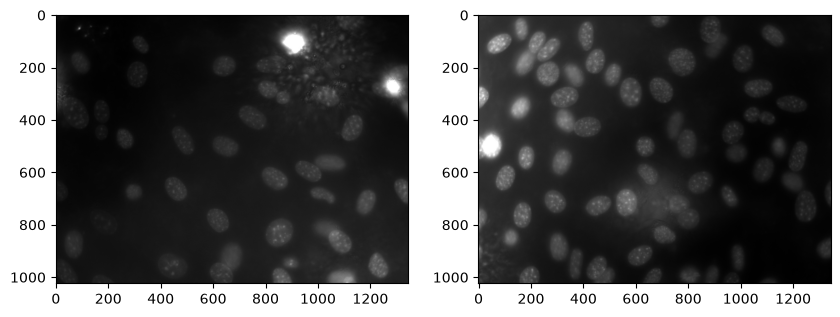

In [69]:
dna_33 = plt.imread("data/NIH3T3/im/dna-33.png")
dna_44 = plt.imread("data/NIH3T3/im/dna-44.png")
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(dna_33, "gray")
plt.subplot(1, 2, 2)
plt.imshow(dna_44, "gray")

---

**[Task 1.1.]()** Implement `create_data_matrix`:

In [70]:
int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0]))

1344

In [71]:
def create_data_matrix(img, patch_sizes) :
    X = np.zeros((int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0])), int(patch_sizes[0]**2)))
    blocks = skimage.util.view_as_blocks(img, block_shape = patch_sizes)
    for x in range(blocks.shape[0]) :
        for y in range(blocks.shape[1]) :
            X[int((x*blocks.shape[1])+y),:] = blocks[x,y].flatten()
    return X


**[Task 1.2.]()** Implement `create_gt_labels_vector`:

In [72]:
def create_gt_labels_vector(gt, patch_sizes) :
    V = np.zeros((int(((dna_33.shape[1])/patch_sizes[0]) * ((dna_33.shape[0])/patch_sizes[0])), 1))
    blocks = skimage.util.view_as_blocks(gt, block_shape = patch_sizes)
    for x in range(blocks.shape[0]) :
        for y in range(blocks.shape[1]) :
            if (sum(blocks[x,y].flatten()) / blocks[x,y].flatten().shape) > 0.5 :
                V[int((x*blocks.shape[1])+y)] = 1
            elif (sum(blocks[x,y].flatten()) / blocks[x,y].flatten().shape) == 0 :
                V[int((x*blocks.shape[1])+y)] = -1
            else :
                V[int((x*blocks.shape[1])+y)] = 0
    return V

**[Task 1.3.]()** Create the SVM classifier:

In [73]:
clf = make_pipeline(StandardScaler(), SVC(class_weight='balanced', gamma=0.1))

**[Task 1.3 (a).]()** Create the data matrices for the images `dna-33` and `dna-44`:

In [74]:
X_dna_33 = create_data_matrix(dna_33, patch_sizes)
X_dna_44 = create_data_matrix(dna_44, patch_sizes)

**[Task 1.3 (b).]()** Create the corresponding ground truth label vectors:

In [75]:
gt_33 = plt.imread("data/NIH3T3/gt/33.png")
gt_44 = plt.imread("data/NIH3T3/gt/44.png")

V_gt_33 = create_gt_labels_vector(gt_33, patch_sizes)
V_gt_44 = create_gt_labels_vector(gt_44, patch_sizes)

**[Task 1.3 (c).]()** Create the *combined* data matrices and ground truth label vectors:

In [76]:
X_train_stacked = np.concatenate((X_dna_33, X_dna_44))
V_train_stacked = np.concatenate((V_gt_33, V_gt_44))
X_train_stacked = X_train_stacked[V_train_stacked[:, -1] != 0]
V_train_stacked = V_train_stacked[V_train_stacked[:, -1] != 0]

**[Task 1.3 (d).]()** Train the classifier using the data matrix and label vectors from above:

In [77]:
clf.fit(X_train_stacked, V_train_stacked.flatten())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[-1., 1.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1024
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


**[Task 1.4.]()** Implement the function `predict_image`:

In [78]:
np.zeros(patch_sizes, dtype=bool)

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(32, 32))

In [79]:
def predict_image(img, patch_sizes):
    X = create_data_matrix(img, patch_sizes)
    F = clf.predict(X)
    background = np.zeros(patch_sizes, dtype=bool)
    foreground = np.ones(patch_sizes, dtype=bool)
    bi_img = np.zeros(img.shape, dtype=bool)
    for x in range(int(img.shape[0] / patch_sizes[0])) :
        for y in range(int(img.shape[1] / patch_sizes[1])) :
            if  F[int((x * img.shape[1] / patch_sizes[1]) + y)] == 1 :
                bi_img[int(x * patch_sizes[0]) : int((x+1) * patch_sizes[0]), int(y * patch_sizes[1]) : int((y+1) * patch_sizes[1])] = foreground
            else :
                bi_img[int(x * patch_sizes[0]) : int((x+1) * patch_sizes[0]), int(y * patch_sizes[1]) : int((y+1) * patch_sizes[1])] = background
    return bi_img

Test your implementation:

In [80]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img, patch_sizes)

In [81]:
print(seg.shape == img.shape)
img.dtype

True


dtype('float32')

/var/folders/nl/0lggqn6d7qgdn8q_wz9ph3600000gn/T/ipykernel_91699/1684334352.py:6: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))
/var/folders/nl/0lggqn6d7qgdn8q_wz9ph3600000gn/T/ipykernel_91699/1684334352.py:6: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  seg_bd = np.logical_xor(morph.binary_dilation(seg, selem), morph.binary_erosion(seg, selem))


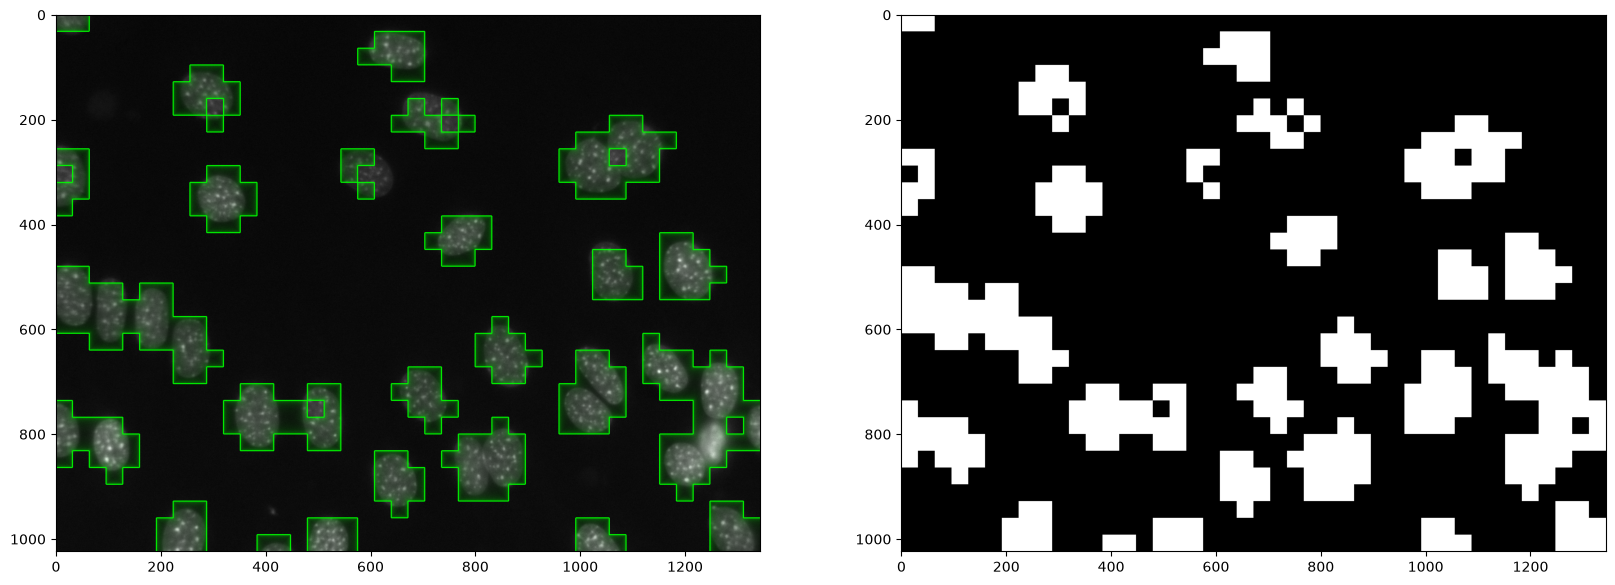

In [82]:
img = plt.imread(f'data/NIH3T3/im/dna-0.png')
seg = predict_image(img, patch_sizes)

plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.imshow(blend_result(img, seg))
plt.subplot(1, 2, 2)
plt.imshow(seg, "gray")

**[Task 1.5.]()** Perform batch processing:

In [83]:
def dice_coefficient(picture, ground_truth):
    return (2 * (picture * ground_truth).sum()) / (picture.sum() + ground_truth.sum())

In [84]:
imgs = {}
imgs_gt = {}
segs = {}
dice_scores = {}
for i in [28,29,33,44,46,49] :
    imgs[i] = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    imgs_gt[i] = plt.imread(f'data/NIH3T3/gt/{i}.png')
    segs[i] = predict_image(imgs[i], patch_sizes)
    dice_scores[i] = dice_coefficient(segs[i], imgs_gt[i])
    print(str(i) + ": " + str(dice_scores[i]))
print("Dice Mittelwert: " + str(np.mean(list(dice_scores.values()))))


28: 0.7209812219847866
29: 0.6600878826245624
33: 0.6778978154021594
44: 0.7125355936692934
46: 0.6171491101827866
49: 0.6889506296603939
Dice Mittelwert: 0.6796003755873304


Der mittlere Dice Score ist schlechter als beim Otsu thresholding, aber das liegt wahrscheinlich an den großen patches.